In [104]:


from langchain_huggingface import ChatHuggingFace,HuggingFaceEndpoint,HuggingFaceEmbeddings

from langchain_community.document_loaders import TextLoader,DirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document
from langchain_chroma import Chroma


from pathlib import Path
from dotenv import load_dotenv
load_dotenv()


from langchain_groq import ChatGroq
from langchain_ollama import ChatOllama


In [105]:
from langchain_groq import ChatGroq

llm1 = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.1
)
llm2 = ChatOllama(
    model="qwen2.5:1.5b",
    temperature=0.1
)
embedder = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6456.92it/s]


In [106]:
loader = DirectoryLoader(
    path=Path("./cleaned-transcripts/").as_posix(),
    loader_cls=TextLoader,
    show_progress=True
)
docs = loader.load()

100%|██████████| 14/14 [00:00<00:00, 2376.95it/s]


In [107]:
chunker = RecursiveCharacterTextSplitter(
    chunk_size =500,
    chunk_overlap=50
)
chunks = chunker.split_documents(docs)
print(len(chunks))

2617


In [108]:
vector_store = Chroma(
    collection_name="rag-demo",
    embedding_function=embedder,
    persist_directory=Path("./Saved-embeddings").as_posix()
)
vector_store.add_documents(chunks)
retriever = vector_store.as_retriever(search_kwargs={"k":3})


In [109]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,List
from langchain_core.output_parsers import StrOutputParser

In [110]:
class RagState(TypedDict):
    query:str
    retrieved_docs: list[Document] 
    prompt: ChatPromptTemplate 
    context:str
    response:str

In [ ]:
def retrieve(state:RagState):
    retrievd_docs = retriever.invoke(state["query"])
    context = '\n\n'.join([doc.page_content for doc in retrievd_docs])
    return {'retrieved_docs':retrievd_docs,'context':context}




In [ ]:
def augumentation(state:RagState):
    
    prompt = ChatPromptTemplate.from_messages([
        ('system',"""You are a helpfull assistant.Answer the query based on the given context only.If u dont know the answer say I Dont Know.dont not add unnecessary extra infor mation or dont hallucinate"""),
        ("human","context:{context}\n\n query:{query}")
    ])
    return{"prompt":prompt}

In [127]:
def generate_response(state:RagState):
    prompt = state["prompt"]
    query = state['query']
    context =state['context']
    rag_chain = prompt | llm1 | StrOutputParser()
    response = rag_chain.invoke({"context":context,'query':query})
    return{"response":response}

In [129]:
graph = StateGraph(RagState)
graph.add_node('retrieve',retrieve)
graph.add_node('augumentation',augumentation)
graph.add_node('generate',generate_response)

graph.add_edge(START,"retrieve")
graph.add_edge('retrieve','augumentation')
graph.add_edge('augumentation','generate')
graph.add_edge('generate',END)

workflow = graph.compile()

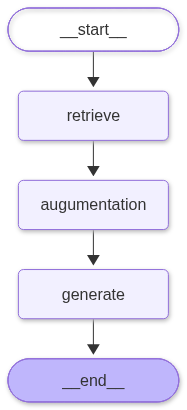

In [130]:
workflow

In [135]:
result = workflow.invoke({"query":"What is regression testing"})

In [136]:
print(result["response"])

Regression testing is a type of testing performed after changes (such as bug fixes or new features) are made to a software system. It involves re‑running previously executed tests to ensure that the existing functionality still works as expected and that the recent changes have not introduced new defects.
